# Asociación y Agrupamiento — Infarto de Miocardio

**Minería de datos**  
Prof. Elizabeth Leon Guzman  
Estudiante: David Julian Bustos Cortes · dbustos@unal.edu.co

---

Este notebook corresponde al segundo avance del proyecto. Parte del preprocesamiento realizado en la entrega anterior e incorpora dos nuevas etapas: **reglas de asociación** (Apriori y FP-Growth) y **agrupamiento** (K-Means, DBSCAN, GMM y agrupamiento jerárquico).

El dataset es el [Myocardial Infarction Complications Dataset](https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications) del repositorio UCI: 1700 pacientes con 111 variables clínicas y 12 variables objetivo (11 complicaciones binarias + causa de muerte multiclase).


## 1. Instalación de dependencias

In [ ]:
%%capture
!pip install efficient_apriori mlxtend ucimlrepo iterative-stratification --quiet

## 2. Importaciones

In [ ]:
import warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import seaborn as sns
import networkx as nx
import time

from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import OrdinalEncoder
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
    adjusted_mutual_info_score
)
from sklearn.tree import DecisionTreeClassifier
from scipy.cluster import hierarchy
from scipy.spatial.distance import pdist

from efficient_apriori import apriori
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

pd.set_option("display.max_columns", None)

## 3. Carga del dataset

In [ ]:
# obtener el dataset
myocardial_infarction_complications = fetch_ucirepo(id=579)

# datos (como dataframes de pandas)
X_raw = myocardial_infarction_complications.data.features.copy()
target_columns = myocardial_infarction_complications.data.targets.columns.tolist()
y_raw = pd.DataFrame(myocardial_infarction_complications.data.targets, columns=target_columns)

# definir lista de variables numéricas y categóricas
numeric_cols = [
    "AGE", "S_AD_KBRIG", "D_AD_KBRIG", "S_AD_ORIT", "D_AD_ORIT",
    "K_BLOOD", "NA_BLOOD", "ALT_BLOOD", "AST_BLOOD", "KFK_BLOOD",
    "L_BLOOD", "ROE"
]
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]

# corregir tipos de datos
X_raw[numeric_cols] = X_raw[numeric_cols].apply(pd.to_numeric, errors="coerce")
X_raw[categorical_cols] = X_raw[categorical_cols].apply(pd.Categorical)
y_raw = y_raw.apply(pd.Categorical)

data = pd.concat([X_raw, y_raw], axis=1)
print("Shape inicial:", data.shape)
print("Target columns:", target_columns)

Shape inicial: (1700, 123)
Target columns: ['FIBR_PREDS', 'PREDS_TAH', 'JELUD_TAH', 'FIBR_JELUD', 'A_V_BLOK', 'OTEK_LANC', 'RAZRIV', 'DRESSLER', 'ZSN', 'REC_IM', 'P_IM_STEN', 'LET_IS']


## 4. Imputación de datos faltantes

**Imputación de datos faltantes**

Se implementa una estrategia diferenciada según el tipo y porcentaje de datos faltantes. Para variables categóricas, se aplica imputación sobre las variables con un porcentaje de datos faltantes superior al 30%. Para las demás, los valores NaN se recodifican como "Missing". En las numéricas, se aplica imputación según el grado de ausencia: se reemplaza por mediana cuando el missing es bajo (<15%), por media cuando es moderado (15-30%) y se crea una columna indicadora _missing para preservar la información de ausencia. Las variables con más del 30% de datos faltantes se eliminan.

In [ ]:
# 1. Imputación categórica
missing_pct_cat = data[categorical_cols].isna().mean()
cat_high_missing = missing_pct_cat[missing_pct_cat > 0.30].index.tolist()
categorical_cols = [c for c in categorical_cols if c not in cat_high_missing]
data = data.drop(columns=cat_high_missing)
print("Categóricas eliminadas (>30% missing):", cat_high_missing)

for col in categorical_cols:
    if "Missing" not in data[col].cat.categories:
        data[col] = data[col].cat.add_categories("Missing")
    data[col] = data[col].fillna("Missing")

# 2. Imputación numérica
def missing_pct(df, cols):
    return (df[cols].isna().sum() / len(df) * 100)

pct = missing_pct(data, numeric_cols)
low_missing    = pct[pct < 15].index.tolist()
medium_missing = pct[(pct >= 15) & (pct <= 30)].index.tolist()
high_missing   = pct[pct > 30].index.tolist()

print("\nImputación númerica:")
print("Baja (<15%):", low_missing)
print("Media (15-30%):", medium_missing)
print("Alta (>30%, se eliminan):", high_missing)

# a) imputar mediana en low_missing
for col in low_missing:
    data[col] = data[col].fillna(data[col].median())

# b) crear columna _missing y rellenar con media la variable.
for col in medium_missing:
    ind_col = col + "_missing"
    data[ind_col] = data[col].isna().astype(int).astype("category")
    categorical_cols.append(ind_col)
    data[col] = data[col].fillna(data[col].mean())

# c) eliminar variables con > 30% missing
data = data.drop(columns=high_missing)
numeric_cols_clean = [c for c in low_missing + medium_missing if c in data.columns]

print(f"\nShape tras imputación: {data.shape}")

Categóricas eliminadas (>30% missing): ['IBS_NASL', 'NA_KB', 'NOT_NA_KB', 'LID_KB']

Imputación númerica:
Baja (<15%): ['AGE', 'L_BLOOD', 'ROE']
Media (15-30%): ['S_AD_ORIT', 'D_AD_ORIT', 'K_BLOOD', 'NA_BLOOD', 'ALT_BLOOD', 'AST_BLOOD']
Alta (>30%, se eliminan): ['S_AD_KBRIG', 'D_AD_KBRIG', 'KFK_BLOOD']

Shape tras imputación: (1700, 122)


La eliminación de las variables 'S_AD_KBRIG' 'D_AD_KBRIG' se sustenta, además del porcentaje de datos perdidos, sobre el análisis de correlación de variables hecha en el análisis exploratorio. Estas variables están fuertemente correlacionadas con 'S_AD_ORIT' y 'D_AD_ORIT', lo que hace que su eliminación no represente una perdida significativa de la información. La perdida de 'KFK_BLOOD' si representa una perdida de información, pero minima, puesto que esta variable tenia valor en un porcentaje muy mínimo de las instancias.

---

**Nota importante:** las 11 complicaciones y la variable de mortalidad `LET_IS` se excluyen de todas las matrices de features usadas en clustering y asociación. Se reservan exclusivamente para evaluación mediante métricas externas. Incluirlas en el entrenamiento generaría grupos definidos por el outcome -circular e informativamente vacío.

## 5. Asociación

### 5.1 Preparación del dataset para asociación

**Discretización:** Las reglas de asociación requieren ítems discretos, formato que las variables categóricas poseen de forma natural pero que las numéricas continuas deben adquirir mediante discretización. Para lograrlo, se aplicó una discretización supervisada entrenando un árbol de decisión individual de baja profundidad por cada variable continua, tomando la variable LET_IS (mortalidad) como objetivo para extraer sus umbrales de corte.

Esta estrategia reemplaza los métodos tradicionales de intervalos fijos por puntos de quiebre con alto significado clínico, optimizados para identificar el riesgo de muerte. Aunque este enfoque sesga intencionalmente las reglas hacia patrones de desenlace crítico —lo cual es valioso para la gestión hospitalaria—, se garantiza la naturaleza no supervisada del análisis posterior excluyendo por completo a LET_IS y a las 11 complicaciones del conjunto final de transacciones, evitando así tautologías en el modelo.

In [ ]:
# Discretización supervisada de variables numéricas
numeric_for_assoc = [c for c in numeric_cols_clean if c in data.columns]
y_disc = pd.to_numeric(data["LET_IS"], errors="coerce").fillna(0).astype(int)

def supervised_discretize(series, y, max_depth=2):
    """Discretiza una serie numérica usando los cortes de un árbol de decisión."""
    valid = series.notna()
    X_fit = series[valid].values.reshape(-1, 1)
    y_fit = y[valid].values

    dt = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    dt.fit(X_fit, y_fit)

    # extraer umbrales únicos y ordenados
    thresholds = sorted(set(
        t for t in dt.tree_.threshold if t != -2.0
    ))

    if not thresholds:
        median = series.median()
        thresholds = [median]

    bins = [-np.inf] + thresholds + [np.inf]
    labels = []
    for i in range(len(bins) - 1):
        low = f"{bins[i]:.1f}" if bins[i] != -np.inf else "-inf"
        high = f"{bins[i+1]:.1f}" if bins[i+1] != np.inf else "inf"
        labels.append(f"{series.name}_({low}–{high}]")

    discretized = pd.cut(series, bins=bins, labels=labels, include_lowest=True)
    return discretized.astype(str)

# aplicar discretización a las variables numéricas
disc_df = pd.DataFrame(index=data.index)
for col in numeric_for_assoc:
    disc_df[col] = supervised_discretize(data[col], y_disc)

# construir transacciones
cat_for_assoc = [c for c in categorical_cols if c in data.columns
                 and c not in target_columns and not c.endswith("_missing")]

transactions_df = pd.concat([
    data[cat_for_assoc].astype(str).apply(lambda col: col.name + "=" + col),
    disc_df
], axis=1)

print(f"Variables numéricas discretizadas: {disc_df.shape[1]}")
print("La discretización se dió de la siguiente manera:\n")
for col in disc_df:
    print(col, disc_df[col].nunique(), "\n ->", disc_df[col].unique(), end="\n\n")

Variables numéricas discretizadas: 9
La discretización se dió de la siguiente manera:

AGE 4 
 -> ['AGE_(74.5–inf]' 'AGE_(49.5–63.5]' 'AGE_(63.5–74.5]' 'AGE_(-inf–49.5]']

L_BLOOD 4 
 -> ['L_BLOOD_(8.0–8.1]' 'L_BLOOD_(7.4–8.0]' 'L_BLOOD_(8.1–inf]'
 'L_BLOOD_(-inf–7.4]']

ROE 4 
 -> ['ROE_(9.5–31.5]' 'ROE_(-inf–9.5]' 'ROE_(47.5–inf]' 'ROE_(31.5–47.5]']

S_AD_ORIT 4 
 -> ['S_AD_ORIT_(112.5–inf]' 'S_AD_ORIT_(85.0–112.5]' 'S_AD_ORIT_(65.0–85.0]'
 'S_AD_ORIT_(-inf–65.0]']

D_AD_ORIT 4 
 -> ['D_AD_ORIT_(72.5–inf]' 'D_AD_ORIT_(55.0–72.5]' 'D_AD_ORIT_(35.0–55.0]'
 'D_AD_ORIT_(-inf–35.0]']

K_BLOOD 4 
 -> ['K_BLOOD_(4.2–inf]' 'K_BLOOD_(3.0–4.1]' 'K_BLOOD_(4.1–4.2]'
 'K_BLOOD_(-inf–3.0]']

NA_BLOOD 4 
 -> ['NA_BLOOD_(136.8–166.0]' 'NA_BLOOD_(-inf–135.5]' 'NA_BLOOD_(135.5–136.8]'
 'NA_BLOOD_(166.0–inf]']

ALT_BLOOD 3 
 -> ['ALT_BLOOD_(-inf–1.1]' 'ALT_BLOOD_(1.1–2.9]' 'ALT_BLOOD_(2.9–inf]']

AST_BLOOD 4 
 -> ['AST_BLOOD_(0.1–0.7]' 'AST_BLOOD_(-inf–0.1]' 'AST_BLOOD_(0.7–0.8]'
 'AST_BLOOD_(0.8–inf]'

**Selección de características**: Para reducir el vocabulario de ítems sin introducir sesgo supervisado, se seleccionaron las 35 variables más informativas mediante entropía de Shannon. Variables con entropía baja —donde una categoría domina a las demás— aportan poco a las reglas porque sus asociaciones son triviales. Al conservar solo las de mayor entropía se garantiza que cada variable presente variabilidad real entre los pacientes, haciendo el espacio de búsqueda más compacto y las reglas resultantes más significativas.

In [ ]:
# selección no supervisada por entropía: quedarse con las más informativas
from scipy.stats import entropy

def col_entropy(series):
    counts = series.value_counts(normalize=True)
    return entropy(counts)

# cálcular las variables con mayor entropía
entropies = transactions_df.apply(col_entropy).sort_values(ascending=False)
TOP_N = 35
cols_to_keep = entropies.head(TOP_N).index.tolist()
transactions_df = transactions_df[cols_to_keep]
print("Transactions_df shape tras filtro:", transactions_df.shape)

transactions = [
    [str(v) for v in row if str(v) not in ("nan",)
    and "Missing" not in str(v)]
    for _, row in transactions_df.iterrows()
]
print(f"Total transacciones: {len(transactions)}")
print(f"Ejemplo (paciente 0): {transactions[0][:8]}...")

Transactions_df shape tras filtro: (1700, 35)
Total transacciones: 1700
Ejemplo (paciente 0): ['TIME_B_S=4.0', 'DLIT_AG=7.0', 'STENOK_AN=1.0', 'inf_im=0.0', 'ant_im=1.0', 'AGE_(74.5–inf]', 'lat_im=0.0', 'IBS_POST=2.0']...


### 5.2 Apriori

Se aplica el algoritmo Apriori con soporte mínimo de 0.3 y confianza mínima de 0.6. Con estos umbrales se busca un balance entre cobertura (reglas que aplican a al menos el 30% de los pacientes) y precisión (la consecuente ocurre en al menos el 60% de los casos que cumplen el antecedente).


In [ ]:
t0 = time.time()

# método apriori
itemsets_ap, rules_ap = apriori(
    transactions,
    min_support=0.30,
    min_confidence=0.60,
)

t_apriori = time.time() - t0
print(f"Apriori completado en {t_apriori:.2f}s")
print(f"Itemsets frecuentes: {sum(len(v) for v in itemsets_ap.values())}")
print(f"Reglas generadas: {len(rules_ap)}")

# Top reglas por lift
rules_ap_sorted = sorted(rules_ap, key=lambda r: r.lift, reverse=True)

print("\nTop 15 reglas por lift (Apriori):")
print(f"{'Antecedente':<55} {'Consecuente':<30} {'Sup':>6} {'Conf':>6} {'Lift':>6}")
print("-" * 105)
for r in rules_ap_sorted[:15]:
    ant = ", ".join(r.lhs)
    cons = ", ".join(r.rhs)
    print(f"{ant[:53]:<55} {cons[:28]:<30} {r.support:>6.3f} {r.confidence:>6.3f} {r.lift:>6.3f}")

Apriori completado en 9.55s
Itemsets frecuentes: 13167
Reglas generadas: 229439

Top 15 reglas por lift (Apriori):
Antecedente                                             Consecuente                       Sup   Conf   Lift
---------------------------------------------------------------------------------------------------------
FK_STENOK=0.0, S_AD_ORIT_(112.5–inf]                    D_AD_ORIT_(72.5–inf], STENOK    0.318  0.954  2.928
D_AD_ORIT_(72.5–inf], STENOK_AN=0.0                     FK_STENOK=0.0, S_AD_ORIT_(11    0.318  0.977  2.928
STENOK_AN=0.0, S_AD_ORIT_(112.5–inf]                    D_AD_ORIT_(72.5–inf], FK_STE    0.318  0.956  2.928
D_AD_ORIT_(72.5–inf], FK_STENOK=0.0                     STENOK_AN=0.0, S_AD_ORIT_(11    0.318  0.975  2.928
GB=0.0                                                  DLIT_AG=0.0                     0.321  0.902  2.784
DLIT_AG=0.0                                             GB=0.0                          0.321  0.991  2.784
R_AB_2_n=0.0, STENOK_AN

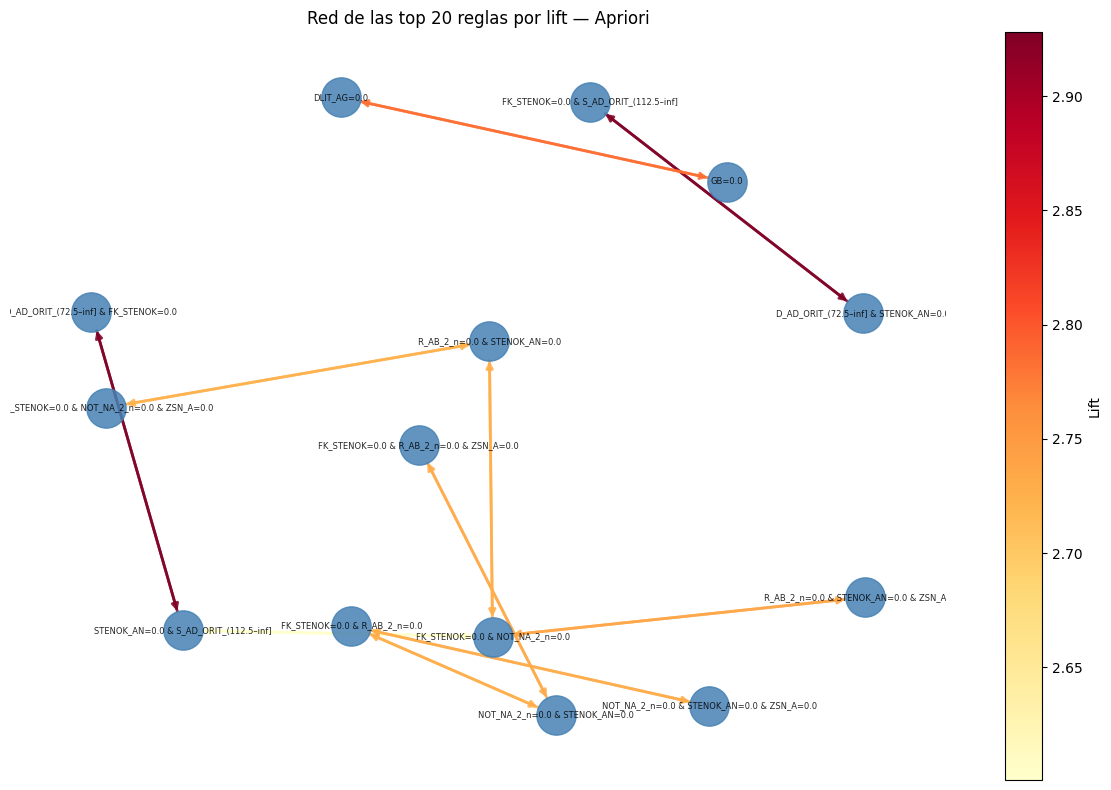

In [ ]:
# Grafo de las top reglas
top_rules = rules_ap_sorted[:20]

G = nx.DiGraph()
for r in top_rules:
    ant_node = " & ".join(r.lhs)
    cons_node = " & ".join(r.rhs)
    G.add_edge(ant_node, cons_node, weight=r.lift, conf=r.confidence)

fig, ax = plt.subplots(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42, k=2)
weights = [G[u][v]["weight"] for u, v in G.edges()]
nx.draw_networkx(
    G, pos, ax=ax,
    node_size=800, node_color="steelblue", font_size=6,
    edge_color=weights, edge_cmap=plt.cm.YlOrRd,
    width=2, alpha=0.85, arrows=True
)
sm = plt.cm.ScalarMappable(cmap=plt.cm.YlOrRd,
     norm=plt.Normalize(vmin=min(weights), vmax=max(weights)))
plt.colorbar(sm, ax=ax, label="Lift")
ax.set_title("Red de las top 20 reglas por lift — Apriori")
ax.axis("off")
plt.tight_layout()
plt.show()

### 5.3 FP-Growth

FP-Growth construye un árbol de prefijos comprimido para evitar la generación explícita de candidatos, lo que lo hace significativamente más eficiente en memoria y tiempo que Apriori para datasets con muchas transacciones. Se usan los mismos umbrales para permitir comparación directa.


In [ ]:
# Preparar formato binario para mlxtend
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_te = pd.DataFrame(te_array, columns=te.columns_)

# método fp-growth
t0 = time.time()
frequent_itemsets_fp = fpgrowth(df_te, min_support=0.30, use_colnames=True)
t_fp = time.time() - t0

rules_fp = association_rules(frequent_itemsets_fp, metric="confidence", min_threshold=0.60)
rules_fp = rules_fp.sort_values("lift", ascending=False).reset_index(drop=True)

print(f"FP-Growth completado en {t_fp:.2f}s")
print(f"Itemsets frecuentes: {len(frequent_itemsets_fp)}")
print(f"Reglas generadas: {len(rules_fp)}")

print("\nTop 15 reglas por lift (FP-Growth):")
print(f"{'Antecedente':<55} {'Consecuente':<30} {'Sup':>6} {'Conf':>6} {'Lift':>6}")
print("-" * 105)

for _, row in rules_fp.head(15).iterrows():
    # Convertir los frozensets de mlxtend a strings separados por comas
    ant = ", ".join(list(row["antecedents"]))
    cons = ", ".join(list(row["consequents"]))

    # Imprimir con el mismo formateo de espacios
    print(f"{ant[:53]:<55} {cons[:28]:<30} {row['support']:>6.3f} {row['confidence']:>6.3f} {row['lift']:>6.3f}")

FP-Growth completado en 98.83s
Itemsets frecuentes: 13167
Reglas generadas: 229439

Top 15 reglas por lift (FP-Growth):
Antecedente                                             Consecuente                       Sup   Conf   Lift
---------------------------------------------------------------------------------------------------------
D_AD_ORIT_(72.5–inf], STENOK_AN=0.0                     S_AD_ORIT_(112.5–inf], FK_ST    0.318  0.977  2.928
S_AD_ORIT_(112.5–inf], FK_STENOK=0.0                    D_AD_ORIT_(72.5–inf], STENOK    0.318  0.954  2.928
D_AD_ORIT_(72.5–inf], FK_STENOK=0.0                     S_AD_ORIT_(112.5–inf], STENO    0.318  0.975  2.928
S_AD_ORIT_(112.5–inf], STENOK_AN=0.0                    D_AD_ORIT_(72.5–inf], FK_STE    0.318  0.956  2.928
DLIT_AG=0.0                                             GB=0.0                          0.321  0.991  2.784
GB=0.0                                                  DLIT_AG=0.0                     0.321  0.902  2.784
FK_STENOK=0.0, NOT

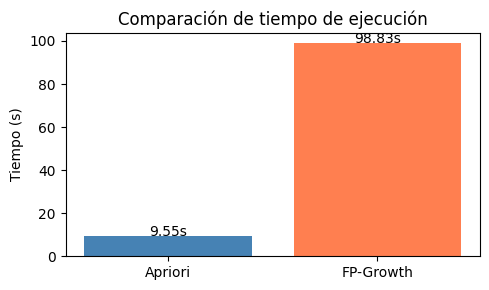


FP-Growth fue 0.1x más rápido que Apriori.


In [ ]:
# Comparación de tiempos
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["Apriori", "FP-Growth"], [t_apriori, t_fp], color=["steelblue", "coral"])
ax.set_ylabel("Tiempo (s)")
ax.set_title("Comparación de tiempo de ejecución")
for i, v in enumerate([t_apriori, t_fp]):
    ax.text(i, v + 0.01, f"{v:.2f}s", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

print(f"\nFP-Growth fue {t_apriori/t_fp:.1f}x más rápido que Apriori.")

### 5.4 Análisis de las reglas más significativas

Las reglas más interesantes no son necesariamente las de mayor lift, sino las que tienen al mismo tiempo soporte relevante (cubren una fracción no trivial de pacientes), confianza alta y lift > 1 (la consecuente ocurre más de lo esperado dado el antecedente). Se presentan y discuten las reglas que cumplen estos tres criterios.


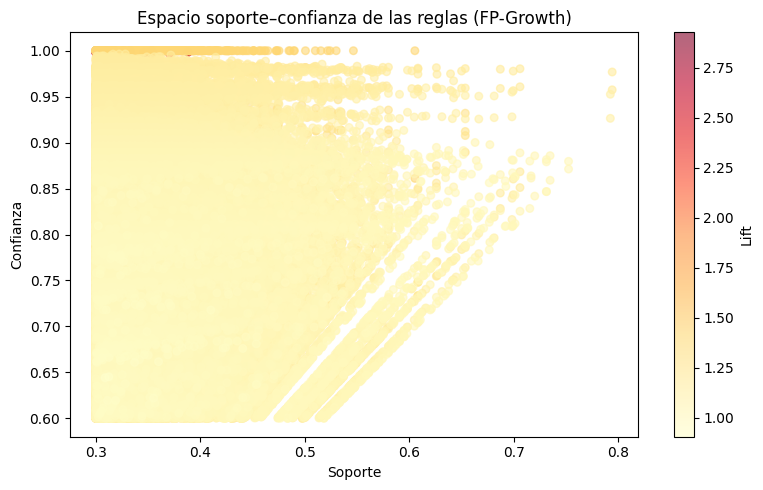

In [ ]:
# Scatter: soporte vs confianza, coloreado por lift
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(
    rules_fp["support"], rules_fp["confidence"],
    c=rules_fp["lift"], cmap="YlOrRd", alpha=0.6, s=30
)
plt.colorbar(sc, ax=ax, label="Lift")
ax.set_xlabel("Soporte")
ax.set_ylabel("Confianza")
ax.set_title("Espacio soporte–confianza de las reglas (FP-Growth)")
plt.tight_layout()
plt.show()

Los 3 grupos de reglas de asociación más importantes son:

* Grupo 1: Presión arterial normal + sin antecedentes de angina
Las reglas con ```S_AD_ORIT_(112.5–inf]```, ```D_AD_ORIT_(72.5–inf]```, ```FK_STENOK=0.0``` y ```STENOK_AN=0.0``` aparecen juntas con lift 2.928. Clínicamente esto describe pacientes que llegan a UCI con presión arterial conservada (sistólica >112.5, diastólica >72.5 mmHg) y sin antecedentes de angina de esfuerzo. Es el perfil del infarto "de novo" —primer evento coronario sin enfermedad isquémica previa conocida— que es coherente porque la ausencia de angina previa implica que no hubo proceso crónico de estenosis gradual.

* Grupo 2: Sin hipertensión + sin duración de hipertensión ```GB=0.0``` → ```DLIT_AG=0```.0 con soporte 0.321 y lift 2.784 es casi tautológica pero clínicamente válida: pacientes sin hipertensión arterial (GB=0) obviamente no tienen duración de hipertensión (DLIT_AG=0). Su presencia alta en el dataset confirma que cerca del 32% de los pacientes ingresaron sin antecedente hipertensivo.

* Grupo 3: Sin dolor recurrente + sin angina + sin insuficiencia cardíaca previa
Las reglas con  ```R_AB_2_n=0.0 ```,  ```STENOK_AN=0.0 ```,  ```ZSN_A=0.0 ```,  ```FK_STENOK=0.0 ``` y  ```NOT_NA_2_n=0.0 ``` describen pacientes sin reaparición del dolor en el segundo día, sin angina previa, sin insuficiencia cardíaca crónica en anamnesis y sin necesidad de AINEs el segundo día. Este es el perfil más interesante: pacientes con evolución hospitalaria favorable temprana y sin comorbilidades cardiovasculares previas, lo que sugiere un infarto agudo sin sustrato crónico subyacente.

En conjunto, las reglas más fuertes no describen pacientes complicados sino el perfil del paciente típico que sobrevive: presión conservada al ingreso, sin angina previa, sin insuficiencia cardíaca crónica, evolución inicial sin dolor recurrente. Esto es consistente con el clustering, como se verá a continuación, —el cluster mayoritario (1569 pacientes) corresponde exactamente a ese perfil de bajo riesgo.

## 6. Clustering

### 6.1 Preparación del dataset para clustering

**One-hot encoding**: Las variables categóricas fueron transformadas mediante codificación One-Hot Encoding, lo cual permite representar cada categoría como una variable binaria independiente. Las variables ordinales fueron codificadas mediante un codificador ordinal.

In [ ]:
# variables ordinales (conservan orden natural)
ordinal_cols = [
    "INF_ANAM", "STENOK_AN", "FK_STENOK", "IBS_POST", "GB", "DLIT_AG",
    "ZSN_A", "ant_im", "lat_im", "inf_im", "post_im", "TIME_B_S",
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n", "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n"
]

# filtrar a las que sobrevivieron la imputación
ordinal_cols = [c for c in ordinal_cols if c in data.columns and c in categorical_cols]
nominal_cols = [c for c in categorical_cols if c not in ordinal_cols and c in data.columns]

# excluir targets y convertir a string
df_features = data.drop(columns=[c for c in target_columns if c in data.columns]).copy()
df_features[categorical_cols] = df_features[categorical_cols].astype(str)

preprocessor = ColumnTransformer(
    transformers=[
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
        ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols)
    ],
    remainder="passthrough"
)
X_enc = preprocessor.fit_transform(df_features)

ohe_cols  = preprocessor.named_transformers_["ohe"].get_feature_names_out(nominal_cols).tolist()
pass_cols = [c for c in df_features.columns if c not in nominal_cols + ordinal_cols]
all_cols  = ohe_cols + ordinal_cols + pass_cols

df_enc = pd.DataFrame(X_enc, columns=all_cols)
print("df_enc shape final:", df_enc.shape)
print(f"  OHE: {len(ohe_cols)} cols | Ordinales: {len(ordinal_cols)} | Passthrough: {len(pass_cols)}")

df_enc shape final: (1700, 263)
  OHE: 233 cols | Ordinales: 21 | Passthrough: 9


In [ ]:
for col in ordinal_cols:
    if col in df_enc.columns:
        # valores únicos para cada variable ordinal
        print(f"{col}: {df_enc[col].nunique()} únicos → {sorted(df_enc[col].dropna().unique())}")

INF_ANAM: 5 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
STENOK_AN: 8 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0)]
FK_STENOK: 6 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
IBS_POST: 4 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
GB: 5 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
DLIT_AG: 9 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]
ZSN_A: 6 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
ant_im: 6 únicos → [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
l

Tras la codificación, el conjunto de datos pasó de 122 variables originales a 263 variables numéricas, debido a la expansión de las variables categóricas en múltiples indicadores binarios.

---

**Normalización:** La normalización de las variables numéricas se realizó considerando la forma de sus distribuciones observadas durante el análisis exploratorio. Las variables con distribución aproximadamente normal (edad, presión arterial y electrolitos) fueron estandarizadas mediante Z-score. En contraste, las variables con asimetría positiva (ALT_BLOOD, AST_BLOOD, L_BLOOD y ROE) fueron transformadas previamente mediante logaritmo natural para reducir la asimetría, y posteriormente estandarizadas mediante Z-score. Este procedimiento permite mejorar la estabilidad numérica de los modelos y evitar que variables con escalas muy diferentes dominen el proceso de aprendizaje.

In [ ]:
normal_cols = ["AGE", "S_AD_ORIT", "D_AD_ORIT", "NA_BLOOD", "K_BLOOD"]
skewed_cols = ["ALT_BLOOD", "AST_BLOOD", "L_BLOOD", "ROE"]

# Filtrar cuáles de las numéricas deseadas están presentes en df_enc
cols_to_scale = [c for c in normal_cols + skewed_cols + ordinal_cols if c in df_enc.columns]
skewed_present = [c for c in skewed_cols if c in df_enc.columns]

# Aplicar transformación logarítmica solo a las numéricas con asimetría en df_enc
df_enc[skewed_present] = np.log1p(df_enc[skewed_present].clip(lower=0))

# Ajustar y transformar con StandardScaler SOLO las columnas numéricas dentro de df_enc
scaler = StandardScaler()
df_enc[cols_to_scale] = scaler.fit_transform(df_enc[cols_to_scale])

print("Normalización aplicada.")
print(f"Variables escaladas: {cols_to_scale}")
print("df_features shape:", df_enc.shape)

Normalización aplicada.
Variables escaladas: ['AGE', 'S_AD_ORIT', 'D_AD_ORIT', 'NA_BLOOD', 'K_BLOOD', 'ALT_BLOOD', 'AST_BLOOD', 'L_BLOOD', 'ROE', 'INF_ANAM', 'STENOK_AN', 'FK_STENOK', 'IBS_POST', 'GB', 'DLIT_AG', 'ZSN_A', 'ant_im', 'lat_im', 'inf_im', 'post_im', 'TIME_B_S', 'R_AB_1_n', 'R_AB_2_n', 'R_AB_3_n', 'NA_R_1_n', 'NA_R_2_n', 'NA_R_3_n', 'NOT_NA_1_n', 'NOT_NA_2_n', 'NOT_NA_3_n']
df_features shape: (1700, 263)


**Selección de características:** Con 263 variables y 1700 instancias el dataset cae en la maldición de la dimensionalidad: las métricas de distancia pierden discriminación y los algoritmos de clustering se vuelven inestables. La selección de características se hace entrenando un Random Forest para cada una de las 11 complicaciones (problema multilabel) y promediando la importancia de cada feature entre todos los modelos. Este enfoque captura variables relevantes para el perfil clínico general del paciente, no solo para un único outcome. Se conservan las **top 40 variables** —suficiente para representar el espacio clínico sin saturar los algoritmos.


Features seleccionadas (top 40): (1700, 40)


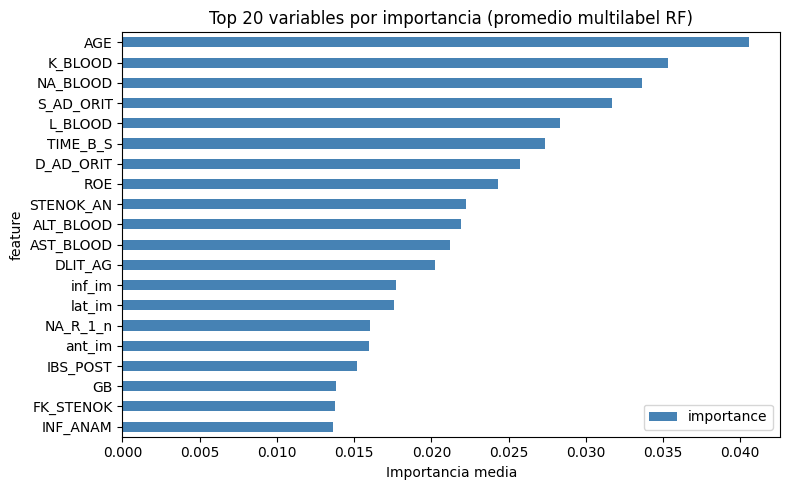

In [ ]:
comp_cols = target_columns[:-1]
Y_comp = data[comp_cols].copy()
for col in comp_cols:
    Y_comp[col] = pd.to_numeric(Y_comp[col], errors="coerce").fillna(0).astype(int)

importances_list = []
for label in comp_cols:
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(df_enc, Y_comp[label])
    importances_list.append(rf.feature_importances_)

mean_imp = np.array(importances_list).mean(axis=0)
feat_imp = pd.DataFrame({"feature": df_enc.columns, "importance": mean_imp})
feat_imp = feat_imp.sort_values("importance", ascending=False).reset_index(drop=True)

TOP_K = 40
selected_features = feat_imp.head(TOP_K)["feature"].tolist()
X_cluster = df_enc[selected_features].copy()

print(f"Features seleccionadas (top {TOP_K}):", X_cluster.shape)

# Top 20 por importancia
fig, ax = plt.subplots(figsize=(8, 5))
feat_imp.head(20).sort_values("importance").plot.barh(x="feature", y="importance", ax=ax, color="steelblue")
ax.set_title("Top 20 variables por importancia (promedio multilabel RF)")
ax.set_xlabel("Importancia media")
plt.tight_layout()
plt.show()

Para el agrupamiento se usa `X_cluster`, la matriz de 40 variables seleccionadas mediante importancia multilabel. Las etiquetas de las 11 complicaciones y `LET_IS` **no entran al entrenamiento**; se usan solo para calcular métricas externas (ARI, NMI) una vez obtenidos los clusters.

Se aplican cuatro algoritmos: **K-Means**, **DBSCAN**, **GMM** y **Agrupamiento jerárquico**. Para cada uno se reportan:
- **Métricas internas**: silhouette score y Davies-Bouldin index.
- **Métricas externas**: ARI y NMI contra `LET_IS` (mortalidad).


### 6.2 Reducción dimensional para visualización (PCA 2D)

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

print(f"Varianza explicada por PC1 y PC2: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Varianza explicada por PC1 y PC2: 26.5%


### 6.3 K-Means

Se usa el método del codo combinado con el silhouette score para elegir el número óptimo de clusters k.


Iniciando entrenamiento para diferentes valores de k

--------------------------------------------------------------------------------
k = 2 | Inercia: 45089.83 | Silueta Promedio: 0.3921


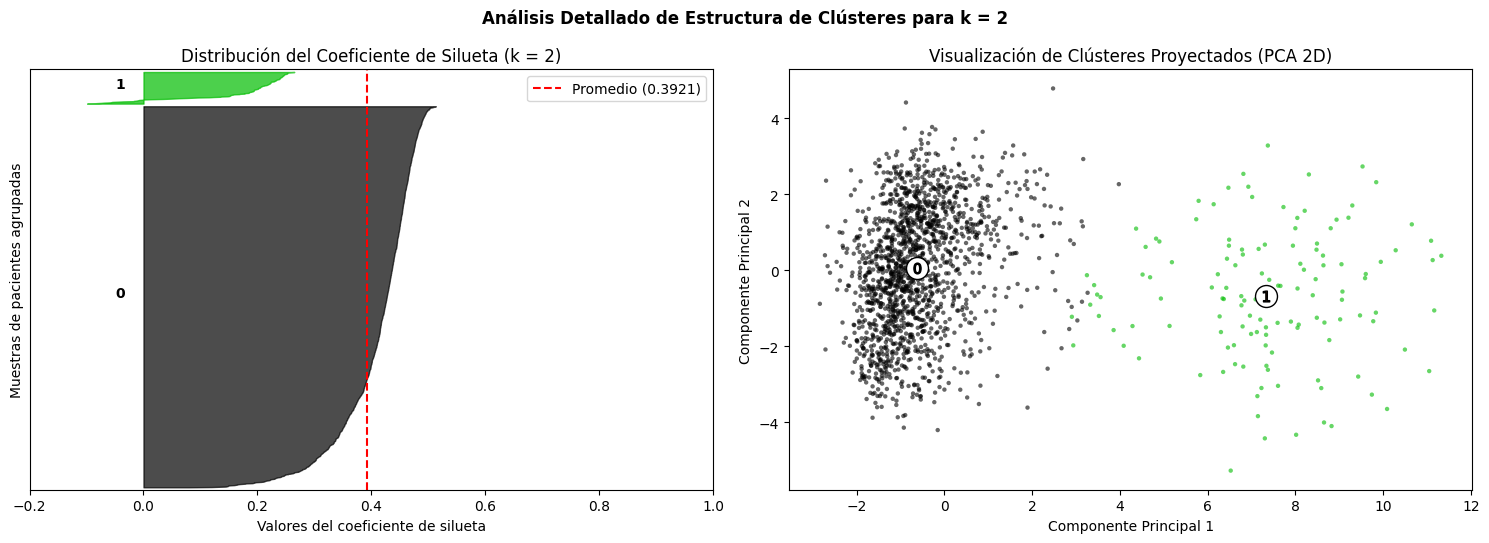

k = 3 | Inercia: 42081.10 | Silueta Promedio: 0.0847


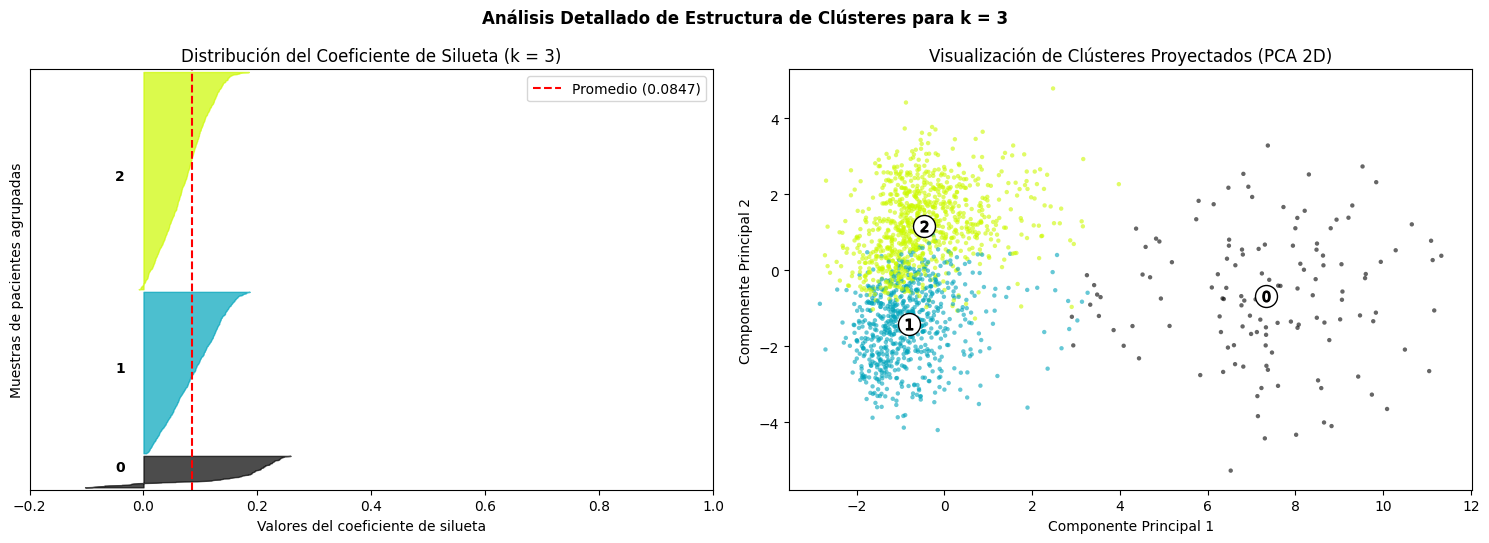

k = 4 | Inercia: 40490.86 | Silueta Promedio: 0.0637


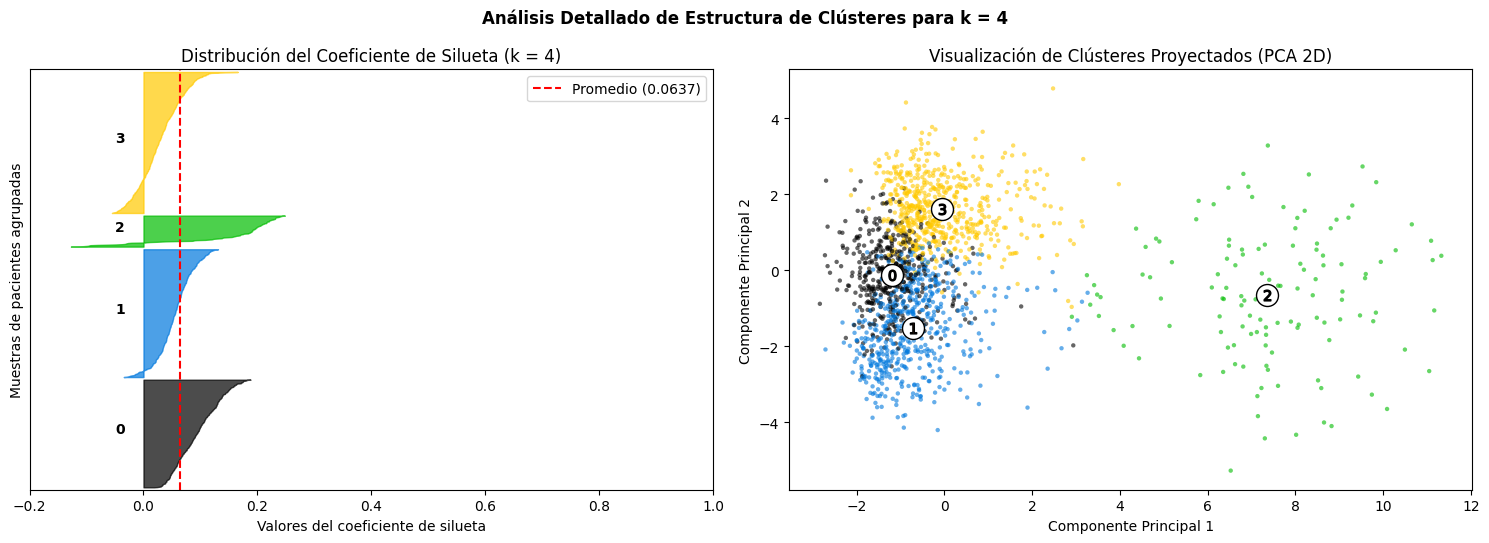

k = 5 | Inercia: 38964.55 | Silueta Promedio: 0.0826


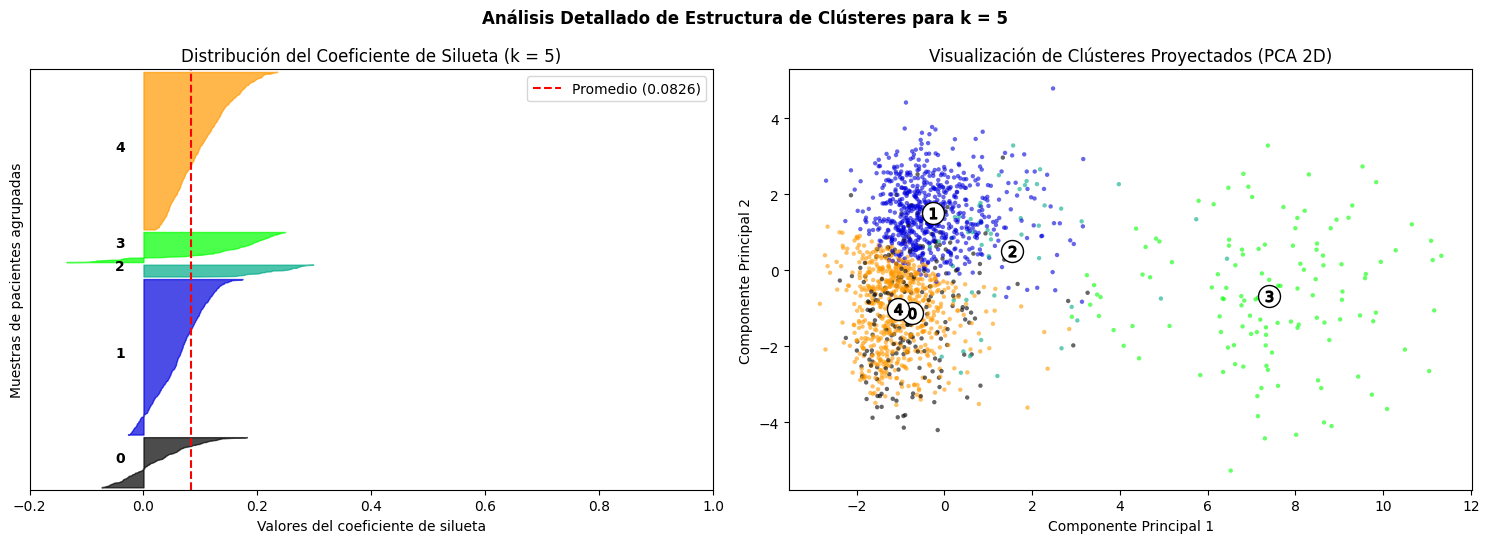

k = 6 | Inercia: 37578.98 | Silueta Promedio: 0.0696


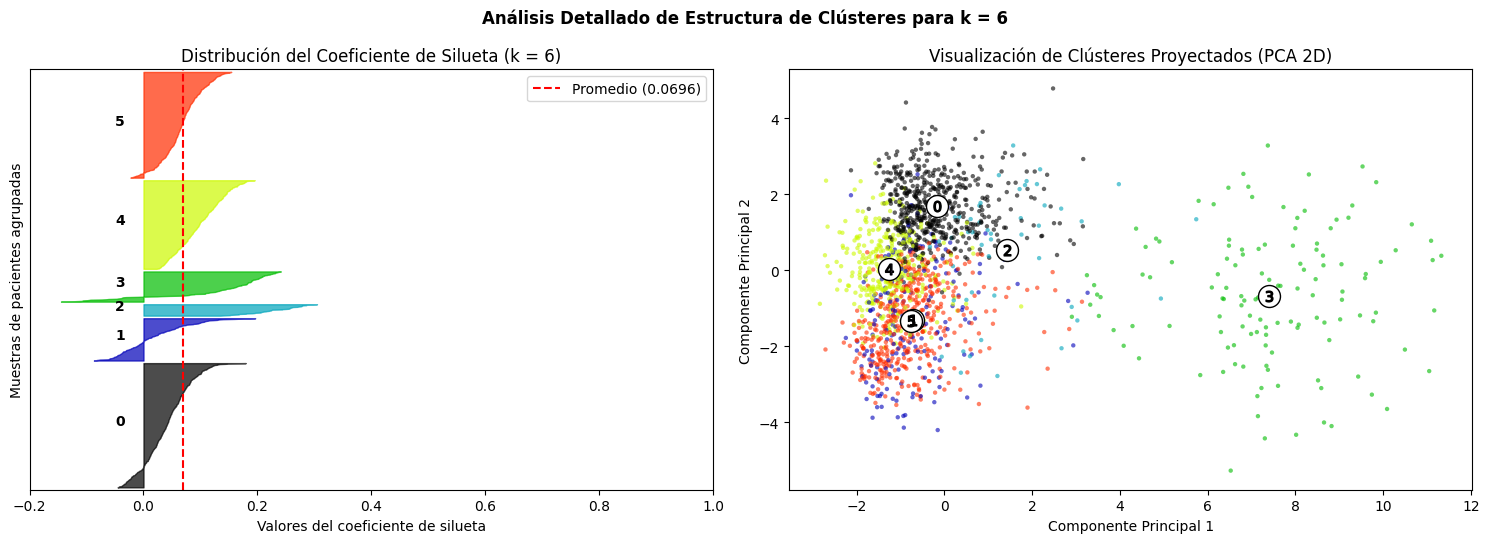

k = 7 | Inercia: 36643.94 | Silueta Promedio: 0.0680
k = 8 | Inercia: 35904.76 | Silueta Promedio: 0.0629
k = 9 | Inercia: 35163.43 | Silueta Promedio: 0.0627
k = 10 | Inercia: 34593.59 | Silueta Promedio: 0.0600
k = 11 | Inercia: 33965.82 | Silueta Promedio: 0.0633

Análisis Completado. Métricas generales:



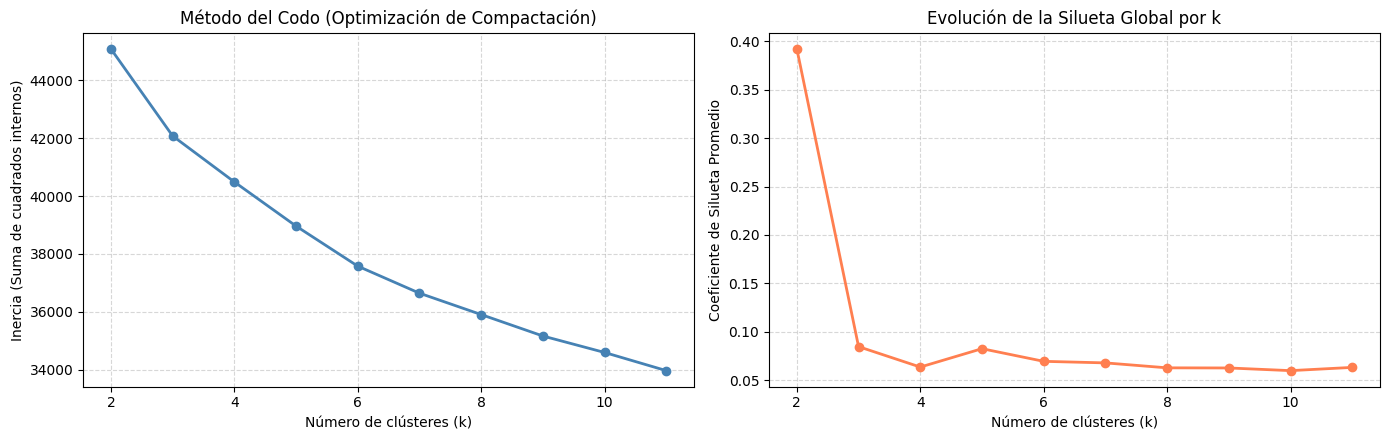

--> k óptimo matemático puro (Máximo Global): 2


In [ ]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

X_eval = X_cluster.values
K_range = range(2, 12)
range_detailed = [2, 3, 4, 5, 6]

inertias = []
sil_scores = []

print("Iniciando entrenamiento para diferentes valores de k\n")
print("-" * 80)

for k in K_range:
    # 1. Entrenar KMeans para este k
    clusterer = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = clusterer.fit_predict(X_eval)

    # 2. Calcular y acumular métricas globales
    inertia_val = clusterer.inertia_
    silhouette_avg = silhouette_score(X_eval, cluster_labels)

    inertias.append(inertia_val)
    sil_scores.append(silhouette_avg)

    print(f"k = {k} | Inercia: {inertia_val:.2f} | Silueta Promedio: {silhouette_avg:.4f}")

    # 3. Gráficas de detalle usando X_pca calculado previamente
    if k in range_detailed:
        fig, (ax_sil, ax_scatter) = plt.subplots(1, 2, figsize=(15, 5.5))

        # Configuración del gráfico de siluetas individuales
        ax_sil.set_xlim([-0.2, 1])
        ax_sil.set_ylim([0, len(X_eval) + (k + 1) * 10])

        sample_silhouette_values = silhouette_samples(X_eval, cluster_labels)

        y_lower = 10
        for i in range(k):
            ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
            ith_cluster_silhouette_values.sort()

            size_cluster_i = ith_cluster_silhouette_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / k)
            ax_sil.fill_betweenx(
                np.arange(y_lower, y_upper),
                0,
                ith_cluster_silhouette_values,
                facecolor=color,
                edgecolor=color,
                alpha=0.7,
            )

            ax_sil.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontweight="bold")
            y_lower = y_upper + 10

        ax_sil.set_title(f"Distribución del Coeficiente de Silueta (k = {k})")
        ax_sil.set_xlabel("Valores del coeficiente de silueta")
        ax_sil.set_ylabel("Muestras de pacientes agrupadas")
        ax_sil.axvline(x=silhouette_avg, color="red", linestyle="--", label=f"Promedio ({silhouette_avg:.4f})")
        ax_sil.legend(loc="upper right")
        ax_sil.set_yticks([])
        ax_sil.set_xticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8, 1])

        # Configuración del Scatterplot usand
        colors = cm.nipy_spectral(cluster_labels.astype(float) / k)
        ax_scatter.scatter(
            X_pca[:, 0], X_pca[:, 1], marker=".", s=40, lw=0, alpha=0.6, c=colors, edgecolor="k"
        )

        # Proyectar los centroides usando el objeto pca existente
        centers_pca = pca.transform(clusterer.cluster_centers_)
        ax_scatter.scatter(
            centers_pca[:, 0], centers_pca[:, 1], marker="o", c="white", alpha=1, s=250, edgecolor="k"
        )

        for i, c in enumerate(centers_pca):
            ax_scatter.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=60, edgecolor="k")

        ax_scatter.set_title("Visualización de Clústeres Proyectados (PCA 2D)")
        ax_scatter.set_xlabel("Componente Principal 1")
        ax_scatter.set_ylabel("Componente Principal 2")

        plt.suptitle(
            f"Análisis Detallado de Estructura de Clústeres para k = {k}",
            fontsize=12,
            fontweight="bold",
        )
        plt.tight_layout()
        plt.show()

print("\n" + "="*80)
print("Análisis Completado. Métricas generales:")
print("="*80 + "\n")

# ==========================================
# Gráficas de codo y silueta.
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(K_range, inertias, marker="o", color="steelblue", linewidth=2)
ax1.set_xlabel("Número de clústeres (k)")
ax1.set_ylabel("Inercia (Suma de cuadrados internos)")
ax1.set_title("Método del Codo (Optimización de Compactación)")
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(K_range, sil_scores, marker="o", color="coral", linewidth=2)
ax2.set_xlabel("Número de clústeres (k)")
ax2.set_ylabel("Coeficiente de Silueta Promedio")
ax2.set_title("Evolución de la Silueta Global por k")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

best_k_global = K_range[np.argmax(sil_scores)]
print(f"--> k óptimo matemático puro (Máximo Global): {best_k_global}")

Para la selección del número óptimo de clústeres, se evaluaron de forma combinada la inercia (método del codo) y el coeficiente de silueta. El silhouette alcanza su máximo en k=2 con un valor de 0.392, notablemente superior a cualquier otro valor evaluado. El método del codo confirma esta elección: la mayor reducción de inercia ocurre precisamente en el paso de k=2 a k=3 (de 45089 a 42081), tras lo cual la curva desciende de forma progresiva sin inflexiones claras. Desde el punto de vista clínico, una bipartición permite distinguir un perfil de paciente de bajo riesgo frente a uno de alto riesgo, lo cual resulta interpretable y accionable en un contexto hospitalario.

K-Means (k=2)
  Silhouette:      0.3921
  Davies-Bouldin:  1.4338
  ARI (vs LET_IS): 0.5124
  NMI (vs LET_IS): 0.3905



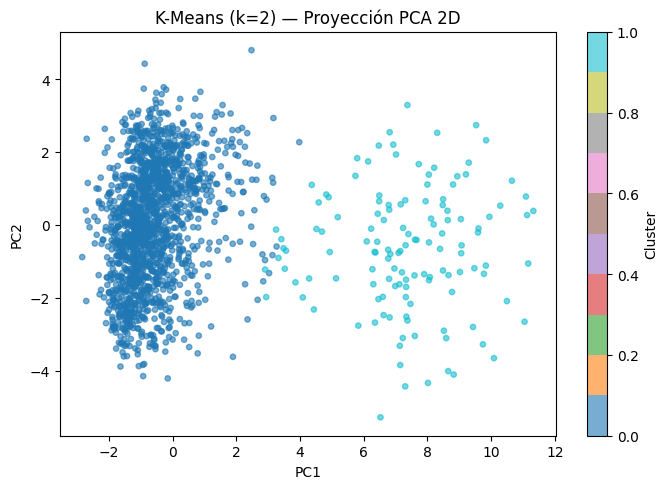

In [ ]:
# Modelo final K-Means
best_k = 2
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=20)
labels_km = km_final.fit_predict(X_cluster)

sil_km = silhouette_score(X_cluster, labels_km)
db_km  = davies_bouldin_score(X_cluster, labels_km)

y_ext = pd.to_numeric(data["LET_IS"], errors="coerce").fillna(0).astype(int)
y_ext_binario = (y_ext != 0).astype(int)

ari_km = adjusted_rand_score(y_ext_binario, labels_km)
nmi_km = normalized_mutual_info_score(y_ext_binario, labels_km)

print(f"K-Means (k={best_k})")
print(f"  Silhouette:      {sil_km:.4f}")
print(f"  Davies-Bouldin:  {db_km:.4f}")
print(f"  ARI (vs LET_IS): {ari_km:.4f}")
print(f"  NMI (vs LET_IS): {nmi_km:.4f}", end="\n\n")

fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap="tab10", s=15, alpha=0.6)
plt.colorbar(scatter, ax=ax, label="Cluster")
ax.set_title(f"K-Means (k={best_k}) — Proyección PCA 2D")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [ ]:
for label in sorted(set(labels_km)):
    print(f"Cluster {label}: {(labels_km == label).sum()} pacientes")

Cluster 0: 1569 pacientes
Cluster 1: 131 pacientes


K-Means con k=2 produjo una partición con buena cohesión interna (silhouette = 0.392, Davies-Bouldin = 1.433) y una alineación notable con el desenlace clínico binarizado: vivo vs. fallecido (ARI = 0.512, NMI = 0.391). Estos resultados indican que el espacio de features seleccionadas captura estructura real relacionada con la mortalidad, aun sin haber utilizado LET_IS en el entrenamiento. El cluster 0 agrupa 1569 pacientes y corresponde predominantemente al perfil de supervivientes, mientras que el cluster 1 concentra 131 pacientes con perfiles de mayor riesgo. El desbalance entre grupos es consistente con la distribución natural del dataset, donde la mortalidad intrahospitalaria representa una minoría de los casos.

### 6.4 DBSCAN

DBSCAN es sensible a los hiperparámetros `eps` (radio de vecindad) y `min_samples`. Se usa la heurística de la curva de distancias al k-ésimo vecino para estimar `eps`, y se exploran algunos valores de `min_samples`.


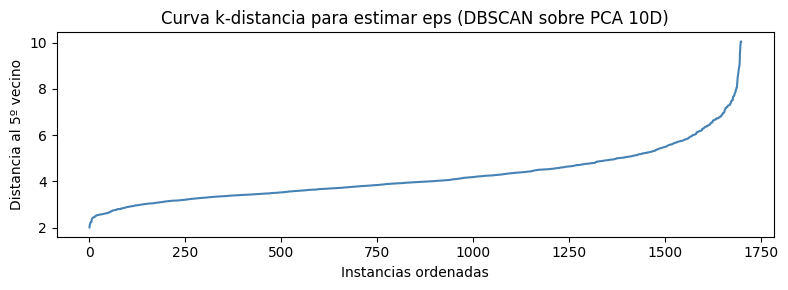

In [ ]:
from sklearn.neighbors import NearestNeighbors

# Heurística k-distancia para eps
nbrs = NearestNeighbors(n_neighbors=5).fit(X_cluster)
distances, _ = nbrs.kneighbors(X_cluster)
k_distances = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(k_distances, color="steelblue")
ax.set_xlabel("Instancias ordenadas")
ax.set_ylabel("Distancia al 5º vecino")
ax.set_title("Curva k-distancia para estimar eps (DBSCAN sobre PCA 10D)")
plt.tight_layout(); plt.show()

La gráfica presenta un comportamiento en forma de S donde la distancia al quinto vecino se mantiene en un ascenso progresivo y controlado hasta aproximadamente eps=7.0, punto de inflexión a partir del cual la curva se dispara verticalmente hacia las instancias más atípicas, sugiriendo ese valor como umbral candidato para el radio de vecindad.

In [ ]:
from itertools import product

eps_values = [3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0]
min_samples_values = [3, 4, 5, 7, 10, 15]

results_db = []
for eps, min_s in product(eps_values, min_samples_values):
    db = DBSCAN(eps=eps, min_samples=min_s)
    lbs = db.fit_predict(X_cluster)
    n_clusters = len(set(lbs)) - (1 if -1 in lbs else 0)
    n_noise = (lbs == -1).sum()
    sil = silhouette_score(X_cluster[lbs != -1], lbs[lbs != -1]) if n_clusters >= 2 else np.nan
    results_db.append({"eps": eps, "min_samples": min_s, "n_clusters": n_clusters, "noise": n_noise, "silhouette": sil})

df_db = pd.DataFrame(results_db).sort_values("silhouette", ascending=False)
display(df_db.head(15))

,eps,min_samples,n_clusters,noise,silhouette
24,7.0,3,2,14,0.405714
30,8.0,3,2,5,0.402170
31,8.0,4,2,5,0.402170
21,6.0,7,2,98,0.378319
22,6.0,10,2,100,0.377067
23,6.0,15,2,104,0.376617
25,7.0,4,3,15,0.328492
8,4.0,5,4,579,0.271973
6,4.0,3,5,548,0.269543
14,5.0,5,3,215,0.267024


DBSCAN (eps=6, min_samples=7)
  Clusters encontrados: 2
  Ruido (outliers):     98
  Silhouette:           0.3783
  Davies-Bouldin:       1.1654
  ARI (vs LET_IS):      0.3469
  NMI (vs LET_IS):      0.2806



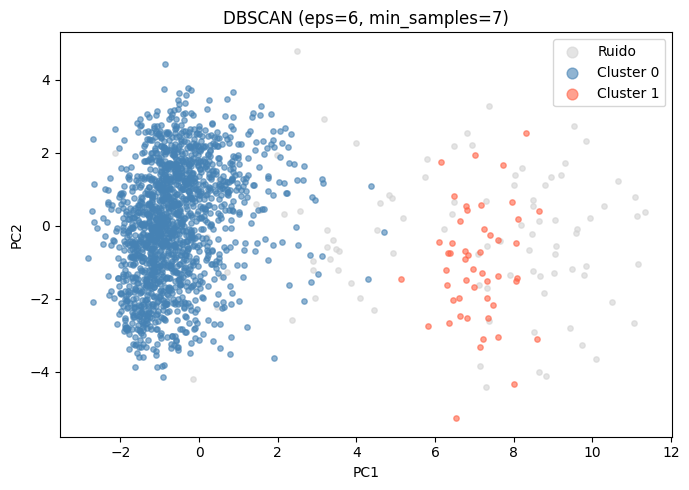

In [ ]:
# Modelo final DBSCAN
best_eps = 6
best_min_samples = 7

db_final = DBSCAN(eps=best_eps, min_samples=best_min_samples)
labels_db = db_final.fit_predict(X_cluster)

mask_valid = labels_db != -1
n_cl_db = len(set(labels_db)) - 1

if n_cl_db >= 2:
    sil_db = silhouette_score(X_cluster[mask_valid], labels_db[mask_valid])
    db_score = davies_bouldin_score(X_cluster[mask_valid], labels_db[mask_valid])
    ari_db = adjusted_rand_score(y_ext_binario[mask_valid], labels_db[mask_valid])
    nmi_db = normalized_mutual_info_score(y_ext_binario[mask_valid], labels_db[mask_valid])
else:
    sil_db = db_score = ari_db = nmi_db = np.nan

print(f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})")
print(f"  Clusters encontrados: {n_cl_db}")
print(f"  Ruido (outliers):     {(labels_db == -1).sum()}")
print(f"  Silhouette:           {sil_db:.4f}")
print(f"  Davies-Bouldin:       {db_score:.4f}")
print(f"  ARI (vs LET_IS):      {ari_db:.4f}")
print(f"  NMI (vs LET_IS):      {nmi_db:.4f}", end="\n\n")

fig, ax = plt.subplots(figsize=(7, 5))
color_map = {-1: "lightgrey", 0: "steelblue", 1: "tomato"}
label_map = {-1: "Ruido", 0: "Cluster 0", 1: "Cluster 1"}
for label, color in color_map.items():
    mask = labels_db == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, s=15, alpha=0.6, label=label_map[label])

ax.set_title(f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(markerscale=2)
plt.tight_layout(); plt.show()

In [ ]:
for label in sorted(set(labels_db)):
    nombre = "Ruido" if label == -1 else f"Cluster {label}"
    print(f"{nombre}: {(labels_db == label).sum()} pacientes")

Ruido: 98 pacientes
Cluster 0: 1552 pacientes
Cluster 1: 50 pacientes


DBSCAN con eps=6eps=6
eps=6 y min_samples=7min\_samples=7
min_samples=7 sobre el espacio original de 40 features identificó 2 clusters con buena cohesión interna (silhouette = 0.378, Davies-Bouldin = 1.165) y una correlación moderada con el desenlace binarizado (ARI = 0.347, NMI = 0.281). El cluster 0 agrupa 1552 pacientes correspondientes al perfil de bajo riesgo, mientras que el cluster 1 concentra 50 pacientes de alto riesgo, con 98 instancias clasificadas como ruido —casos atípicos que no se ajustan a ninguno de los dos perfiles.

### 6.5 Gaussian Mixture Model (GMM)

GMM modela cada cluster como una distribución gaussiana, permitiendo clusters de forma elipsoidal y asignaciones probabilísticas. Se elige el número de componentes mediante BIC (criterio de información bayesiano), que penaliza la complejidad del modelo.


Componentes: 2 | BIC: 42432.68 | AIC: 33073.22
Componentes: 3 | BIC: -22644.71 | AIC: -36686.62
Componentes: 4 | BIC: -16905.24 | AIC: -35629.59
Componentes: 5 | BIC: -8164.45 | AIC: -31571.25
Componentes: 6 | BIC: 5506.01 | AIC: -22583.24
Componentes: 7 | BIC: -10764.22 | AIC: -43535.92
Componentes: 8 | BIC: -3148.95 | AIC: -40603.09
Componentes: 9 | BIC: -4315.54 | AIC: -46452.14
Componentes: 10 | BIC: -10051.54 | AIC: -56870.58
Componentes: 11 | BIC: -9751.89 | AIC: -61253.38


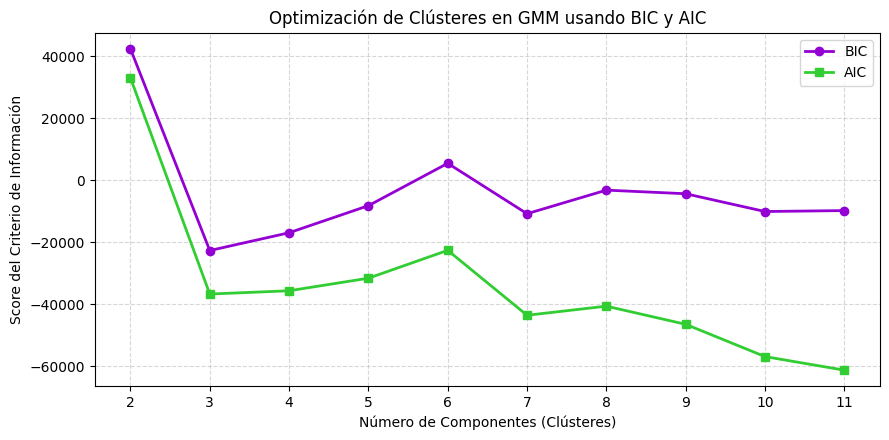

k óptimo por BIC: 3


In [ ]:
# Selección de componentes por BIC
bic_scores = []
aic_scores = []

for k in K_range:
    gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=42, n_init=5)
    gmm.fit(X_cluster)

    bic_scores.append(gmm.bic(X_cluster))
    aic_scores.append(gmm.aic(X_cluster))

    print(f"Componentes: {k} | BIC: {bic_scores[-1]:.2f} | AIC: {aic_scores[-1]:.2f}")

plt.figure(figsize=(9, 4.5))
plt.plot(K_range, bic_scores, marker="o", label="BIC", color="darkviolet", linewidth=2)
plt.plot(K_range, aic_scores, marker="s", label="AIC", color="limegreen", linewidth=2)

plt.xlabel("Número de Componentes (Clústeres)")
plt.ylabel("Score del Criterio de Información")
plt.title("Optimización de Clústeres en GMM usando BIC y AIC")
plt.xticks(K_range)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

best_k_gmm = K_range[np.argmin(bic_scores)]
print(f"k óptimo por BIC: {best_k_gmm}")

GMM (k=3)
  Silhouette:      0.0753
  Davies-Bouldin:  2.8669
  ARI (vs LET_IS): 0.1608
  NMI (vs LET_IS): 0.2113



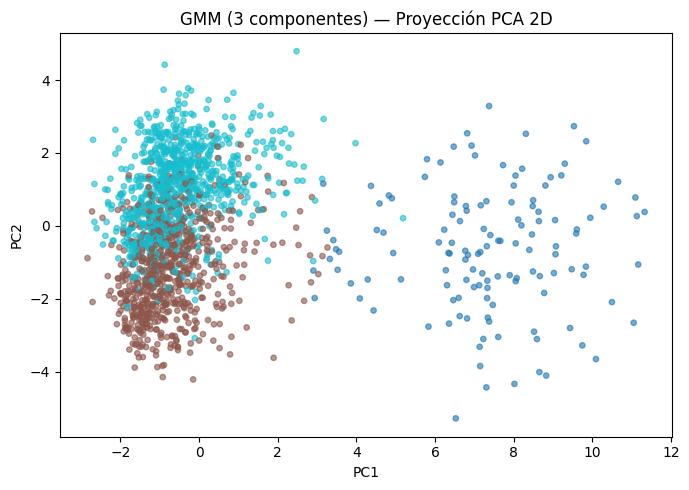

In [ ]:
# Modelo final GMM
gmm_final = GaussianMixture(n_components=best_k_gmm, covariance_type="tied", random_state=42, n_init=10)
labels_gmm = gmm_final.fit_predict(X_cluster)

sil_gmm = silhouette_score(X_cluster, labels_gmm)
db_gmm  = davies_bouldin_score(X_cluster, labels_gmm)
ari_gmm = adjusted_rand_score(y_ext_binario, labels_gmm)
nmi_gmm = normalized_mutual_info_score(y_ext_binario, labels_gmm)

print(f"GMM (k={best_k_gmm})")
print(f"  Silhouette:      {sil_gmm:.4f}")
print(f"  Davies-Bouldin:  {db_gmm:.4f}")
print(f"  ARI (vs LET_IS): {ari_gmm:.4f}")
print(f"  NMI (vs LET_IS): {nmi_gmm:.4f}", end="\n\n")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gmm, cmap="tab10", s=15, alpha=0.6)
ax.set_title(f"GMM ({best_k_gmm} componentes) — Proyección PCA 2D")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [ ]:
for label in sorted(set(labels_gmm)):
    print(f"Cluster {label}: {(labels_gmm == label).sum()} pacientes")

Cluster 0: 131 pacientes
Cluster 1: 719 pacientes
Cluster 2: 850 pacientes


El modelo GMM con k=3k=3 componentes, seleccionado mediante el criterio BIC, produjo clusters de tamaño razonable (131, 719 y 850 pacientes) pero con cohesión interna débil (silhouette = 0.075, Davies-Bouldin = 2.867). Las métricas externas muestran una correlación moderada con el desenlace clínico (ARI = 0.161, NMI = 0.211), inferior a K-Means y DBSCAN. Esto sugiere que las distribuciones gaussianas no modelan adecuadamente la geometría de este dataset clínico, donde los perfiles de pacientes no siguen una estructura elipsoidal bien definida en el espacio de features seleccionadas.

### 6.6 Agrupamiento jerárquico

El agrupamiento jerárquico produce un dendrograma que permite visualizar la estructura anidada de los grupos sin necesidad de especificar k de antemano. Se usa enlace de Ward, que minimiza la varianza intra-cluster en cada fusión.


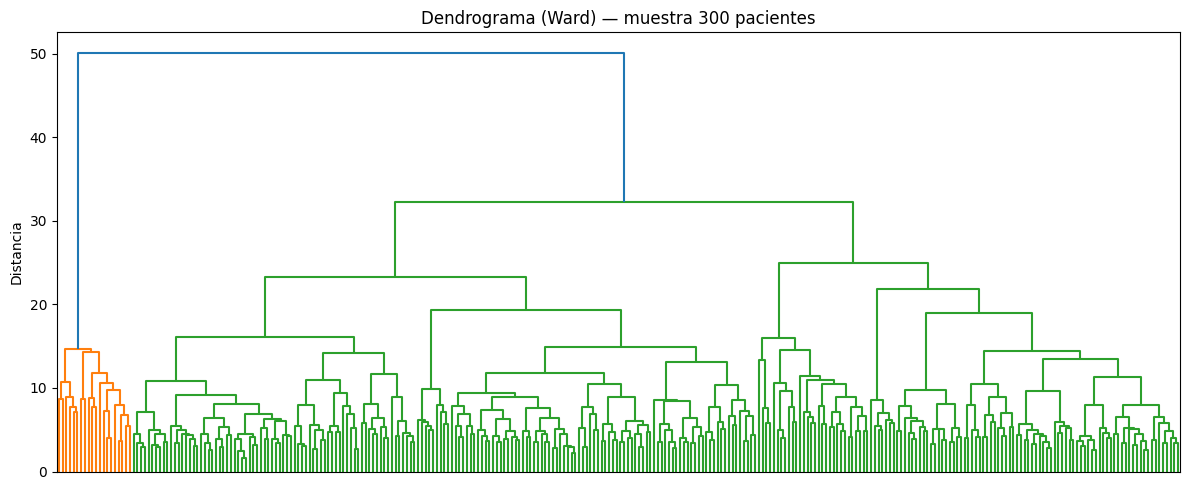

In [ ]:
# Dendrograma Muestra sobre subsample para legibilidad
sample_idx = np.random.choice(len(X_cluster), size=300, replace=False)
Z = hierarchy.linkage(X_cluster.iloc[sample_idx], method="ward")

fig, ax = plt.subplots(figsize=(12, 5))
hierarchy.dendrogram(Z, ax=ax, no_labels=True, color_threshold=0.7*max(Z[:, 2]))
ax.set_title("Dendrograma (Ward) — muestra 300 pacientes")
ax.set_ylabel("Distancia")
plt.tight_layout(); plt.show()

Agrupamiento jerárquico (Ward, k=2)
  Silhouette:      0.3824
  Davies-Bouldin:  1.4291
  ARI (vs LET_IS): 0.5061
  NMI (vs LET_IS): 0.3935



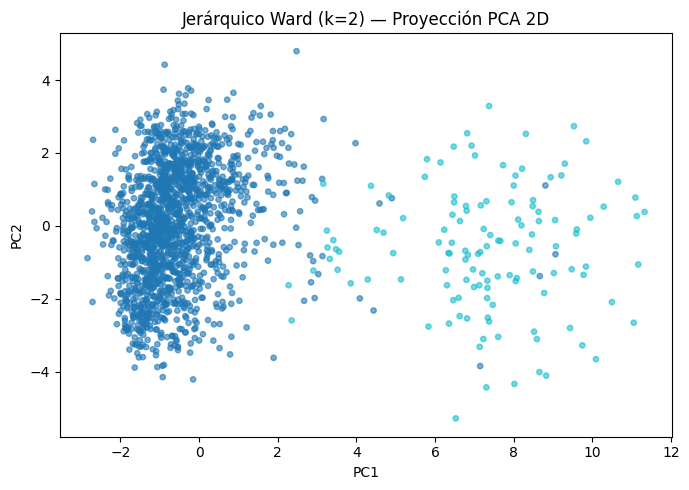

In [ ]:
# Modelo final jerárquico
hc = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
labels_hc = hc.fit_predict(X_cluster)

sil_hc = silhouette_score(X_cluster, labels_hc)
db_hc  = davies_bouldin_score(X_cluster, labels_hc)
ari_hc = adjusted_rand_score(y_ext_binario, labels_hc)
nmi_hc = normalized_mutual_info_score(y_ext_binario, labels_hc)

print(f"Agrupamiento jerárquico (Ward, k={best_k})")
print(f"  Silhouette:      {sil_hc:.4f}")
print(f"  Davies-Bouldin:  {db_hc:.4f}")
print(f"  ARI (vs LET_IS): {ari_hc:.4f}")
print(f"  NMI (vs LET_IS): {nmi_hc:.4f}", end="\n\n")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_hc, cmap="tab10", s=15, alpha=0.6)
ax.set_title(f"Jerárquico Ward (k={best_k}) — Proyección PCA 2D")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [ ]:
for label in sorted(set(labels_hc)):
    print(f"Cluster {label}: {(labels_hc == label).sum()} pacientes")

Cluster 0: 1574 pacientes
Cluster 1: 126 pacientes


El agrupamiento jerárquico con enlace Ward y k=2k=2
k=2 produjo resultados muy similares a K-Means, con buena cohesión interna (silhouette = 0.382, Davies-Bouldin = 1.429) y alta alineación con el desenlace clínico binarizado (ARI = 0.506, NMI = 0.394). La distribución 1574 vs 126 pacientes replica prácticamente la partición encontrada por K-Means (1569 vs 131), lo que refuerza que la estructura binaria bajo riesgo/alto riesgo es robusta y consistente entre algoritmos de naturaleza algorítmica distinta.

### 6.7 Comparación de modelos de agrupamiento

Se comparan los cuatro algoritmos en las cuatro métricas. Un buen modelo de clustering tiene **silhouette alto** (cerca de 1), **Davies-Bouldin bajo** (cerca de 0), y ARI/NMI altos si los clusters tienen correlación con el outcome clínico.


,Silhouette,Davies-Bouldin,ARI,NMI
K-Means,0.3921,1.4338,0.5124,0.3905
DBSCAN,0.3783,1.1654,0.3469,0.2806
GMM,0.0753,2.8669,0.1608,0.2113
Jerárquico,0.3824,1.4291,0.5061,0.3935


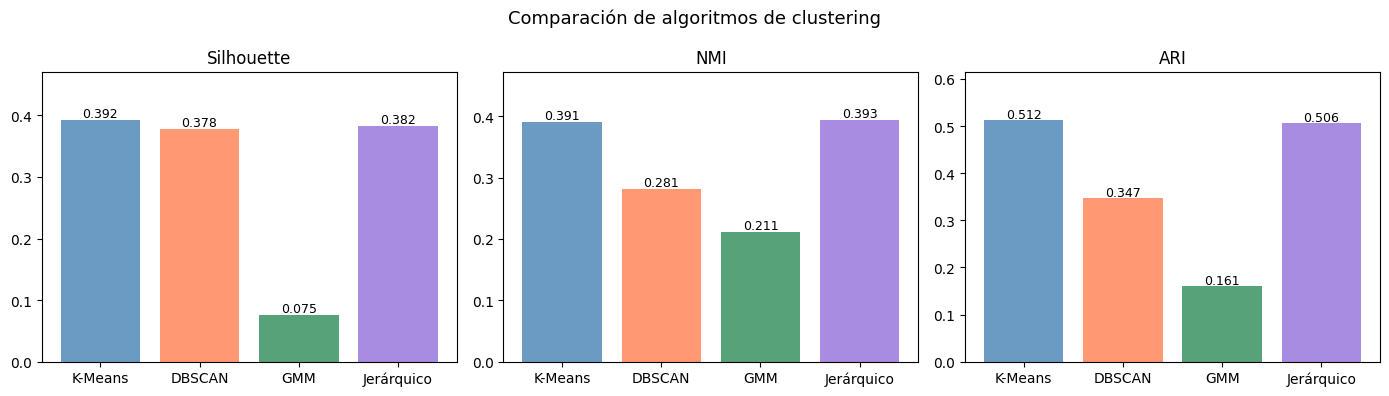

In [ ]:
results = {
    "K-Means":      {"Silhouette": sil_km,  "Davies-Bouldin": db_km,  "ARI": ari_km,  "NMI": nmi_km},
    "DBSCAN":       {"Silhouette": sil_db,  "Davies-Bouldin": db_score,"ARI": ari_db,  "NMI": nmi_db},
    "GMM":          {"Silhouette": sil_gmm, "Davies-Bouldin": db_gmm,  "ARI": ari_gmm, "NMI": nmi_gmm},
    "Jerárquico":   {"Silhouette": sil_hc,  "Davies-Bouldin": db_hc,   "ARI": ari_hc,  "NMI": nmi_hc},
}

df_results = pd.DataFrame(results).T.round(4)
display(df_results)

# Radar chart comparativo
metrics = ["Silhouette", "NMI", "ARI"]
models  = list(results.keys())

fig, axes = plt.subplots(1, len(metrics), figsize=(14, 4))
for ax, metric in zip(axes, metrics):
    vals = [results[m][metric] for m in models]
    colors_bar = ["steelblue", "coral", "seagreen", "mediumpurple"]
    bars = ax.bar(models, vals, color=colors_bar, alpha=0.8)
    ax.set_title(metric)
    ax.set_ylim(0, max(0.1, max(v for v in vals if not np.isnan(v)) * 1.2))
    for bar, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                    f"{v:.3f}", ha="center", fontsize=9)
plt.suptitle("Comparación de algoritmos de clustering", fontsize=13)
plt.tight_layout(); plt.show()

### 6.8 Interpretación de clusters

Una vez identificado el mejor modelo, se analiza qué caracteriza a cada cluster: variables clínicas promedio, distribución de complicaciones, etc.


Perfil numérico (medias):


,AGE,L_BLOOD,ROE,S_AD_ORIT,D_AD_ORIT,K_BLOOD,NA_BLOOD,ALT_BLOOD,AST_BLOOD
cluster,,,,,,,,,
0,61.49,8.63,13.03,137.44,84.66,4.19,136.60,0.48,0.26
1,66.36,9.91,13.10,100.40,59.91,4.19,135.99,0.45,0.27





Perfil categórico (modas):


,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,nr_11,nr_01,nr_02,nr_03,nr_04,nr_07,nr_08,np_01,np_04,np_05,np_07,np_08,np_09,np_10,endocr_01,endocr_02,endocr_03,zab_leg_01,zab_leg_02,zab_leg_03,zab_leg_04,zab_leg_06,O_L_POST,K_SH_POST,MP_TP_POST,SVT_POST,GT_POST,FIB_G_POST,ant_im,lat_im,inf_im,post_im,IM_PG_P,ritm_ecg_p_01,ritm_ecg_p_02,ritm_ecg_p_04,ritm_ecg_p_06,ritm_ecg_p_07,ritm_ecg_p_08,n_r_ecg_p_01,n_r_ecg_p_02,n_r_ecg_p_03,n_r_ecg_p_04,n_r_ecg_p_05,n_r_ecg_p_06,n_r_ecg_p_08,n_r_ecg_p_09,n_r_ecg_p_10,n_p_ecg_p_01,n_p_ecg_p_03,n_p_ecg_p_04,n_p_ecg_p_05,n_p_ecg_p_06,n_p_ecg_p_07,n_p_ecg_p_08,n_p_ecg_p_09,n_p_ecg_p_10,n_p_ecg_p_11,n_p_ecg_p_12,fibr_ter_01,fibr_ter_02,fibr_ter_03,fibr_ter_05,fibr_ter_06,fibr_ter_07,fibr_ter_08,GIPO_K,GIPER_NA,TIME_B_S,R_AB_1_n,R_AB_2_n,R_AB_3_n,NITR_S,NA_R_1_n,NA_R_2_n,NA_R_3_n,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1,0.0,0.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
1,1,0.0,6.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,Missing,Missing,0.0,0.0,Missing,Missing,0.0,Missing,Missing,0.0,0.0,0.0,1.0,0.0,0.0,0.0





Tasa de complicaciones por cluster:


,FIBR_PREDS,PREDS_TAH,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN
cluster,,,,,,,,,,,
0,0.106,0.012,0.026,0.040,0.031,0.092,0.021,0.047,0.251,0.099,0.094
1,0.023,0.008,0.008,0.069,0.069,0.107,0.160,0.008,0.000,0.023,0.008


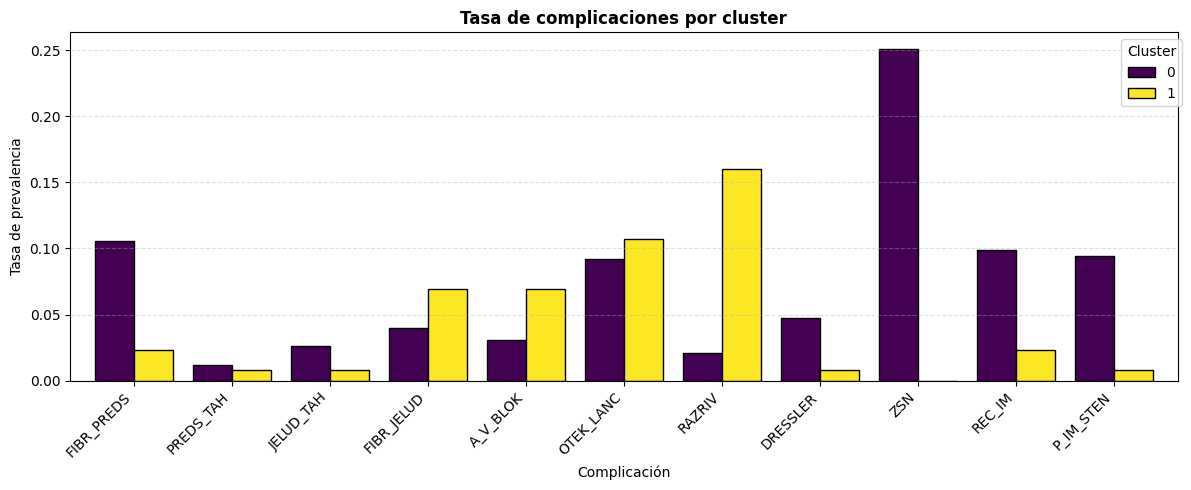

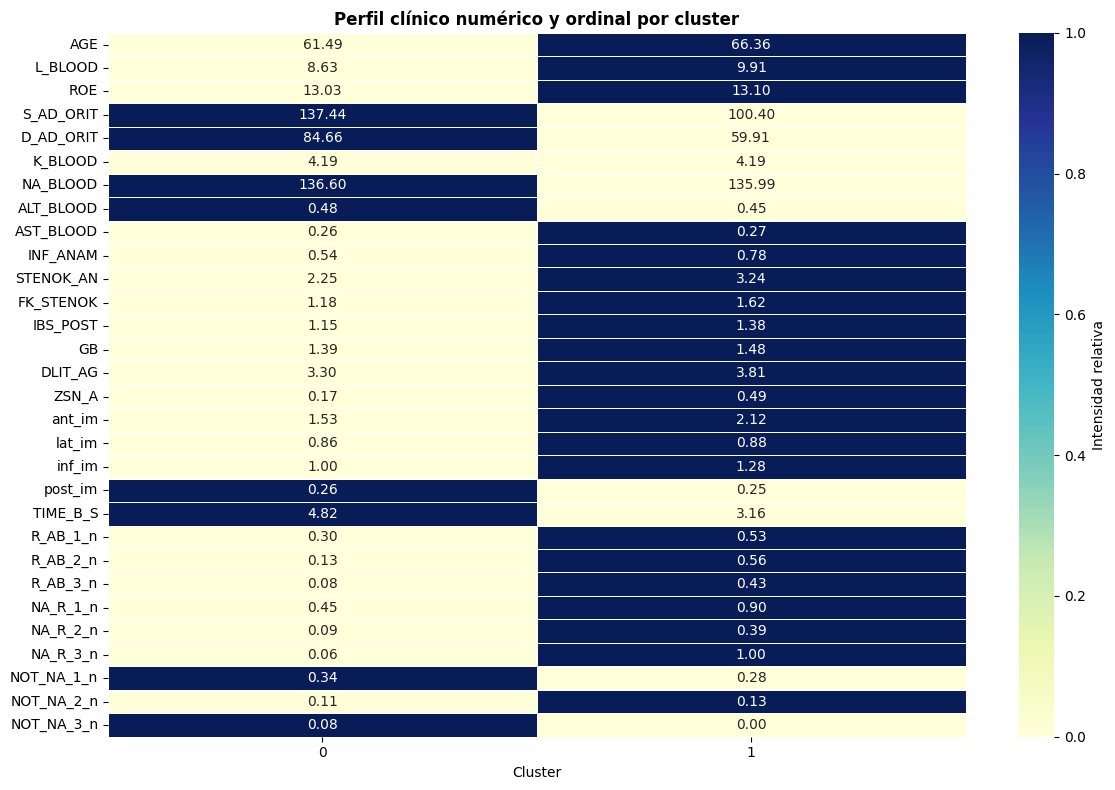

In [ ]:
best_labels = labels_km

# 1. Perfil numérico por cluster
profile_cols = [c for c in numeric_cols_clean if c in data.columns]
df_profile = data[profile_cols].copy()
df_profile["cluster"] = best_labels
profile_num = df_profile.groupby("cluster")[profile_cols].mean().round(2)
print("Perfil numérico (medias):")
display(profile_num)
print("\n")

# 2. Perfil categórico por cluster (moda)
cat_profile_cols = [c for c in categorical_cols if c in data.columns
                    and c not in target_columns
                    and not c.endswith("_missing")]

df_cat = data[cat_profile_cols].copy()
df_cat["cluster"] = best_labels
profile_cat = df_cat.groupby("cluster")[cat_profile_cols].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
)
print("\nPerfil categórico (modas):")
display(profile_cat)
print("\n")

# 3. Tasa de todas las complicaciones por cluster
comp_numeric = Y_comp.copy()
for c in comp_cols:
    comp_numeric[c] = pd.to_numeric(comp_numeric[c], errors="coerce").fillna(0)
comp_numeric["cluster"] = best_labels

comp_rate = comp_numeric.groupby("cluster")[comp_cols].mean().round(3)
print("\nTasa de complicaciones por cluster:")
display(comp_rate)
print("\n")

fig, ax = plt.subplots(figsize=(12, 5))
comp_rate.T.plot(kind="bar", ax=ax, colormap="viridis", edgecolor="black", width=0.8)
ax.set_ylabel("Tasa de prevalencia")
ax.set_xlabel("Complicación")
ax.set_title("Tasa de complicaciones por cluster", fontweight="bold")
ax.legend(title="Cluster", bbox_to_anchor=(1.01, 1))
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

# 4. Heatmap numérico y ordinal por cluster
# Convertir ordinales a numérico para poder calcular media
numeric_and_ordinal = [c for c in numeric_cols_clean + ordinal_cols if c in data.columns]
df_profile2 = data[numeric_and_ordinal].copy()
for c in numeric_and_ordinal:
    df_profile2[c] = pd.to_numeric(df_profile2[c], errors="coerce")
df_profile2["cluster"] = best_labels
profile_num2 = df_profile2.groupby("cluster")[numeric_and_ordinal].mean().round(2)

heatmap_data = profile_num2.T
heatmap_scaled = (heatmap_data - heatmap_data.min(axis=1).values.reshape(-1,1)) / \
                 (heatmap_data.max(axis=1) - heatmap_data.min(axis=1) + 1e-9).values.reshape(-1,1)

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(heatmap_scaled, annot=heatmap_data.round(2), fmt=".2f",
            cmap="YlGnBu", linewidths=0.5, ax=ax,
            cbar_kws={"label": "Intensidad relativa"})
ax.set_title("Perfil clínico numérico y ordinal por cluster", fontweight="bold")
ax.set_xlabel("Cluster")
plt.tight_layout(); plt.show()